# Reference-free deconvolution: Cerebellum

**Data availability.** Mouse cerebellum source cells accompanying the Slide-seq study are available through [Single Cell Portal SCP354](https://singlecell.broadinstitute.org/single_cell/study/SCP354/slide-seq-study). We used the count and cell-type label files distributed with the [RETROFIT benchmark](https://github.com/qunhualilab/retrofit-scripts) to construct the pseudo-spots used in this tutorial.

Learn component proportions and expression profiles directly from raw counts. This example contains **1,000 pseudo-spots, 1,000 genes and 11 known cell types**. Truth is used only after fitting to align components and evaluate recovery. The plotted coordinates form an artificial pseudo-spot grid; they are not anatomical positions in a cerebellar section.

For counts $Y_{ig}$ and exposure $s_i=\sum_gY_{ig}$, the model uses $Y_{ig}\sim\mathrm{Poisson}(s_i(PB)_{ig})$. Rows of $P$ and $B$ sum to one. The core minimizes count-normalized Poisson KL loss plus smoothed graph total variation on $P$. Three count-only initializations (all features, variable features and expression clusters) are aligned by profile cosine similarity and averaged equally before joint refinement. $P$ represents molecular contributions; in reference-free analyses it is not automatically a cell-count fraction.

## 1. Set up

Install spDecon and open this notebook from the cloned repository. The first loading cell downloads the example data automatically.

- `RUN_FIT=False`: load saved fits, display their recorded convergence summary and regenerate metrics and plots on CPU.
- `RUN_FIT=True`: train the model with the settings below. Reference-free training uses the CUDA environment.
- `VERBOSE=True`: show fitting stages, objective (loss), KKT residuals and the final convergence status. Set it to `False` to silence fitting messages.

The setup cell fixes the random seed and enables deterministic execution.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table, saved_fit_summary
from spDecon.reproducibility import set_seed
set_seed(1, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False

VERBOSE = True
print("Mode: full model fitting." if RUN_FIT else "Mode: load saved full fits; no new optimization.")


Mode: load saved full fits; no new optimization.


## 2. Load counts and evaluation truth

Rows are spots, columns are genes. Preserve their order and use raw nonnegative counts; do not log-transform the fitting matrix.

The 1,000 pseudo-spots have known compositions. Their coordinates form an artificial display grid.

In [2]:
path, data = dataset("cerebellum")
y = np.array(data["Y"], dtype=float, order="F")
xy, truth, names = data["coordinates"], data["truth"], data["types"]
print(f"{y.shape[0]:,} spots × {y.shape[1]:,} genes; K={len(names)}")

1,000 spots × 1,000 genes; K=11


## 3. Fit the three-branch consensus and spatial model

The spatial coefficient is calibrated once from the seed-1 consensus without using truth. The graph is symmetric 4-nearest-neighbour, truncated at 1.5 times the median nearest-neighbour spacing. The displayed saved result is the full seed-1 reproduction.

In [3]:
from spDecon.consensus import build_consensus
from spDecon.spatial import spatial_graph, calibrate, refine
if RUN_FIT:
    initial = build_consensus(y, 11, random_state=1, verbose=VERBOSE)
    i, j, w, graph_info = spatial_graph(xy, np.repeat("cerebellum", len(y)))
    calibration = calibrate(y, initial.consensus_proportions, initial.consensus_profiles, i, j, w)
    fit = refine(y, initial.consensus_proportions, initial.consensus_profiles,
                 i, j, w, calibration["spatial_weight"], 1, verbose=VERBOSE)
    p, b = fit.proportions, fit.profiles
    display(fit.diagnostics)
else:
    fitted = np.load(path / "fit.npz")
    p, b = fitted["P"], fitted["B"]
    saved_fit_summary("cerebellum", "RNA")
print("P:", p.shape, "B:", b.shape)

[saved fit] cerebellum/RNA loaded | recorded status=converged | outer_iterations=81 | objective=0.0670145229
[saved fit] This cell loaded a previous full fit; no new optimization was run.


P: (1000, 11) B: (11, 1000)


/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/md1/sxu/spDecon/publictest/.venv/lib/python3.10/site-packages/anndata/utils.py:434: Futur

## 4. Evaluate component recovery

Hungarian matching maximizes the sum of per-type proportion Pearson correlations. This matching is an evaluation operation and does not affect fitting. The mean PCC averages 11 types; RMSE averages all spot-by-type entries. This single seed is not the three-seed mean in the manuscript.

,metric,value
0,Mean type PCC,0.949992
1,RMSE,0.079240


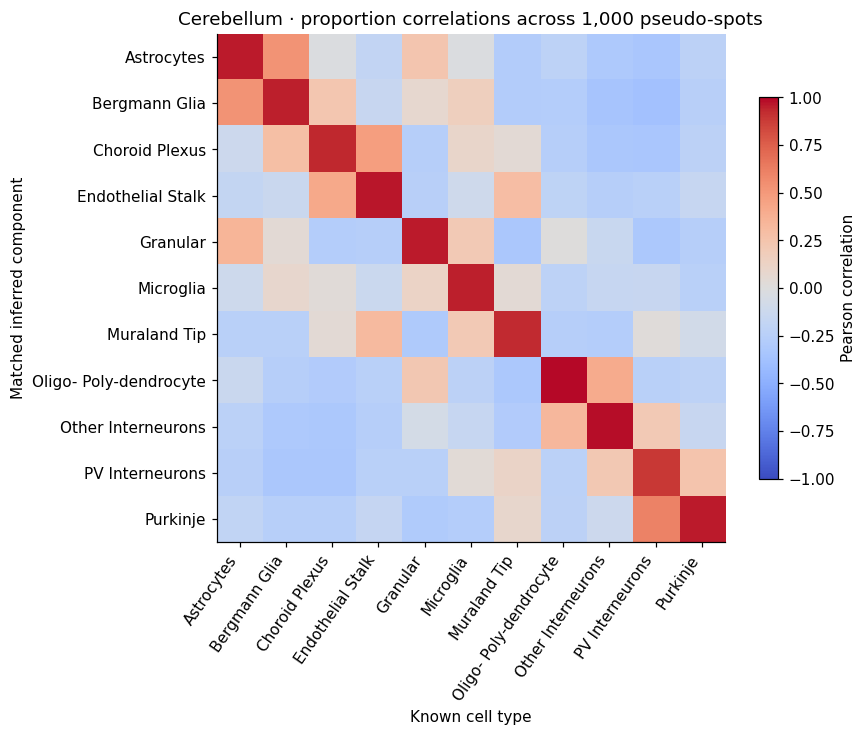

In [4]:
matched, order = align(p, truth)
corr = correlation(matched, truth)
summary = pd.DataFrame({"metric":["Mean type PCC", "RMSE"],
                        "value":[np.diag(corr).mean(), np.sqrt(np.mean((matched-truth)**2))]})
display(save_table(summary, "cerebellum_summary"))
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)),names,rotation=55,ha="right")
ax.set_yticks(range(len(names)),names)
ax.set(xlabel="Known cell type",ylabel="Matched inferred component",title="Cerebellum · proportion correlations across 1,000 pseudo-spots")
fig.colorbar(im,ax=ax,label="Pearson correlation",shrink=.75)
save_figure(fig,"cerebellum_correlation")

## 5. Compare complete compositions with pie plots

Every pie shows one pseudo-spot and sums to one. Both panels use the same cell-type order and colors. All 1,000 spots are displayed.

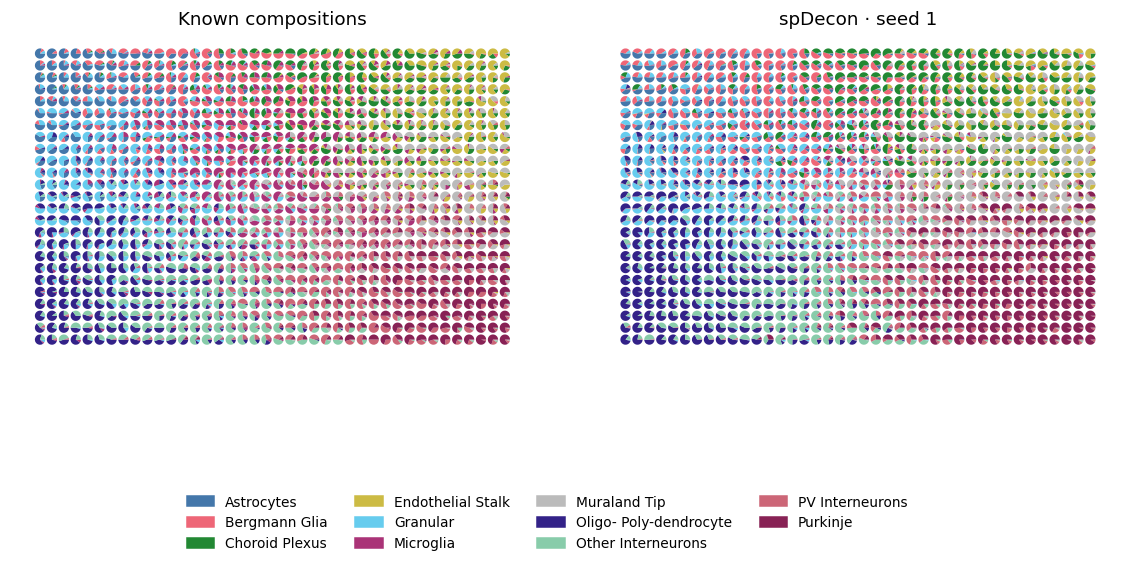

In [5]:
fig, axes = plt.subplots(1,2,figsize=(13,6))
pies(axes[0],xy,truth,"Known compositions",radius=.43)
pies(axes[1],xy,matched,"spDecon · seed 1",radius=.43)
legend(fig,names,columns=4,y=-.04)
fig.subplots_adjust(bottom=.15,wspace=.12)
save_figure(fig,"cerebellum_pies")

## 6. Export and interpret

The fitted profiles describe components on the measured gene panel. Biological annotation requires profile markers or external evidence. The known labels above are available because this is an evaluation dataset.

In [6]:
out = ROOT / "outputs/cerebellum"
out.mkdir(parents=True,exist_ok=True)
pd.DataFrame(matched,index=data["spots"],columns=names).to_csv(out/"proportions.csv")
pd.DataFrame(b[order],index=names,columns=data["genes"]).to_csv(out/"profiles.csv")
print("Exported proportions and profiles to outputs/cerebellum.")

Exported proportions and profiles to outputs/cerebellum.
